# Step 1 - Chunking: where do we cut?

The retriever does not return documents, it returns **chunks**. A question gets a good answer only when
the facts it needs sit together in one chunk.

We take **one real contract**, cut it in **three ways** and read what comes out. Then we repeat the test
on all 40 contracts.

Before running: parse the corpus with `python -m src.ingestion.parsing` (see notebook 00).

In [1]:
import os
import warnings

# Keep the output clean: no progress bars and no notices while the tokenizer loads.
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import re
from collections import Counter
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pymupdf

from src.config import load_config, project_path
from src.ingestion.chunking import Chunk, chunk_document, count_tokens, load_tokenizer
from src.ingestion.parsing import ParsedDocument, load_corpus

config = load_config()
documents = load_corpus(project_path(config.paths.parsed_dir))
tokenizer = load_tokenizer(config.embedding.model_name)  # sizes are counted in tokens of the embedding model
contracts = [document for document in documents if document.path.parts[0] == "01_contratti"]
hero = next(document for document in contracts if "CTR-2024-017" in document.path.name)
STRATEGIES = ["fixed", "recursive", "structural"]

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "font.size": 10}
)

In [3]:
def cut(document: ParsedDocument, strategy: str, **changes: int) -> list[Chunk]:
    """Chunks of a document with one strategy; the other settings are the configured ones unless changed."""
    return chunk_document(document, tokenizer, replace(config.chunking, strategy=strategy, **changes))


print(len(documents), "documents,", len(contracts), "contracts")
print("the contract we look at:", hero.path.name, "-", count_tokens(tokenizer, hero.text), "tokens")
print("configured:", config.chunking)

195 documents, 40 contracts
the contract we look at: CTR-2024-017_Beta_manutenzione-pompe-sommergibili-p7-p9.pdf - 1865 tokens
configured: ChunkingConfig(strategy='structural', max_tokens=300, min_tokens=20, overlap_tokens=40)


## The question

*"How can we leave contract CTR-2024-017, and what does it cost?"*

The answer is Art. 7 of the contract. It holds three facts: the customer's notice, the indemnity,
and the supplier's notice.

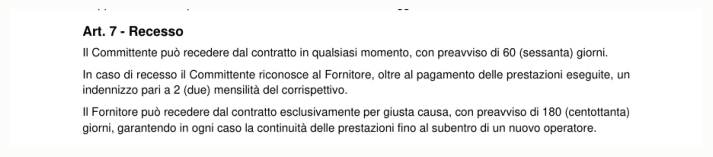

In [4]:
with pymupdf.open(project_path(config.paths.raw_documents_dir) / hero.path) as pdf:
    box = pdf[1].rect
    band = pymupdf.Rect(box.x0, box.height * 0.205, box.x1, box.height * 0.345)
    pixmap = pdf[1].get_pixmap(dpi=110, clip=band)
image = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n)
plt.figure(figsize=(9, 9 * pixmap.height / pixmap.width))
plt.imshow(image)
plt.axis("off")
plt.show()

## Three ways to cut

- **fixed**: a new chunk every 300 tokens, wherever that falls, with 40 tokens repeated between neighbours;
- **recursive**: fill a chunk up to 300 tokens, but cut only between paragraphs (then lines, then sentences);
- **structural**: one chunk per section of the document, that is per article.

Each line below is the start of a chunk. The orange band is Art. 7.

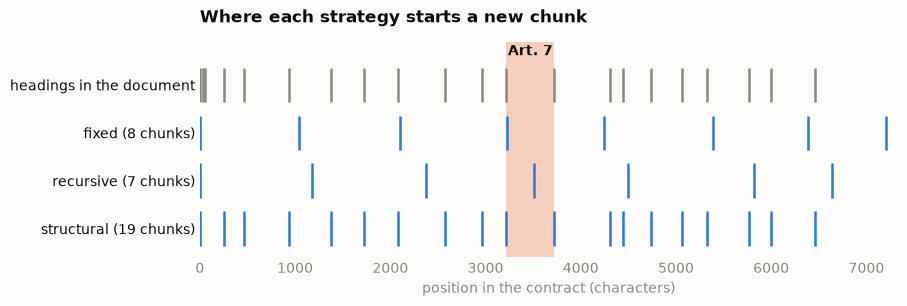

In [5]:
hero_chunks = {strategy: cut(hero, strategy) for strategy in STRATEGIES}
text = hero.text
article_7 = (text.index("## Art. 7"), text.index("## Art. 8"))
rows = {"headings in the document": [match.start() for match in re.finditer(r"^## ", text, re.MULTILINE)]}
for strategy, chunks in hero_chunks.items():
    rows[f"{strategy} ({len(chunks)} chunks)"] = [text.index(chunk.text) for chunk in chunks]

figure, axis = plt.subplots(figsize=(9, 2.8))
axis.axvspan(*article_7, color=ORANGE, alpha=0.3, linewidth=0)
for row, starts in enumerate(rows.values()):
    axis.vlines(starts, row - 0.36, row + 0.36, color=MUTED if row == 0 else BLUE, linewidth=1.8)
axis.text(sum(article_7) / 2, -0.62, "Art. 7", ha="center", color=INK, fontweight="bold")
axis.set_yticks(range(len(rows)), list(rows))
axis.set_ylim(len(rows) - 0.4, -0.9)
axis.set_xlim(0, len(text))
axis.set_xlabel("position in the contract (characters)", color=MUTED)
axis.tick_params(length=0, colors=INK)
axis.tick_params(axis="x", colors=MUTED)
axis.spines[:].set_visible(False)
axis.set_title("Where each strategy starts a new chunk", loc="left", fontweight="bold", pad=14)
plt.show()

`fixed` ignores the headings completely. `recursive` cuts between paragraphs, but not where an article
begins. `structural` cuts exactly on the headings.

Now the chunks themselves: for each strategy, the chunks that hold at least one of the three facts.

In [6]:
FACTS = {
    "customer's notice (60 days)": "preavviso di 60",
    "indemnity (2 monthly fees)": "indennizzo pari a 2",
    "supplier's notice (180 days)": "preavviso di 180",
}

for strategy, chunks in hero_chunks.items():
    print(f"--- {strategy}")
    for chunk in chunks:
        found = [fact for fact, words in FACTS.items() if words in chunk.text]
        if found:
            line = " ".join(chunk.text.split())
            print(f"chunk {chunk.index} of {len(chunks)}: {line[:62]} [...] {line[-62:]}")
            print(f"         holds: {', '.join(found)}")
    print()

--- fixed
chunk 2 of 8: servizio Il Fornitore riceve le chiamate 24 ore su 24, tutti i [...] vviso di 60 (sessanta) giorni. In caso di recesso il Committen
         holds: customer's notice (60 days)
chunk 3 of 8: Art. 7 - Recesso Il Committente può recedere dal contratto in  [...] anzia Il Fornitore garantisce gli interventi eseguiti e i rica
         holds: customer's notice (60 days), indemnity (2 monthly fees), supplier's notice (180 days)

--- recursive
chunk 2 of 7: I tempi decorrono dall'apertura del ticket nel sistema di gest [...] ite, un indennizzo pari a 2 (due) mensilità del corrispettivo.
         holds: customer's notice (60 days), indemnity (2 monthly fees)
chunk 3 of 7: Il Fornitore può recedere dal contratto esclusivamente per giu [...] a dell'intervento. ## Art. 10 - Responsabilità e assicurazione
         holds: supplier's notice (180 days)

--- structural
chunk 9 of 19: ## Art. 7 - Recesso Il Committente può recedere dal contratto  [...] uità delle prestazioni fino 

- `fixed`: chunk 2 stops in the middle of a word ("il Committen") and holds one fact out of three.
  Chunk 3 holds all three, but only because the window happened to start right at Art. 7. It also carries
  Art. 8 and the beginning of Art. 9, cut in the middle of a word again.
- `recursive`: the article is split in two. The half with the supplier's 180 days has lost its heading,
  and the chunk ends with the heading of Art. 10, whose text is in the next chunk.
- `structural`: one chunk, the whole article with its heading and nothing else.

## The same test on all 40 contracts

Every contract has an Art. 7 about withdrawal, about 120 tokens long. For each strategy we count in how
many contracts the whole article ends up in a single chunk, and we repeat the count for many chunk sizes.

In [7]:
def article_body(text: str, number: int) -> str:
    """Text of an article, without its heading."""
    start = text.index("\n", text.index(f"## Art. {number} - "))
    return text[start : text.index("\n## ", start)].strip()


def whole_in(strategy: str, size: int, article: int = 7) -> int:
    """Number of contracts where a single chunk holds the whole article."""
    count = 0
    for contract in contracts:
        body = article_body(contract.text, article)
        count += any(body in chunk.text for chunk in cut(contract, strategy, max_tokens=size))
    return count


SIZES = list(range(150, 501, 25))
whole = {strategy: [whole_in(strategy, size) for size in SIZES] for strategy in STRATEGIES}

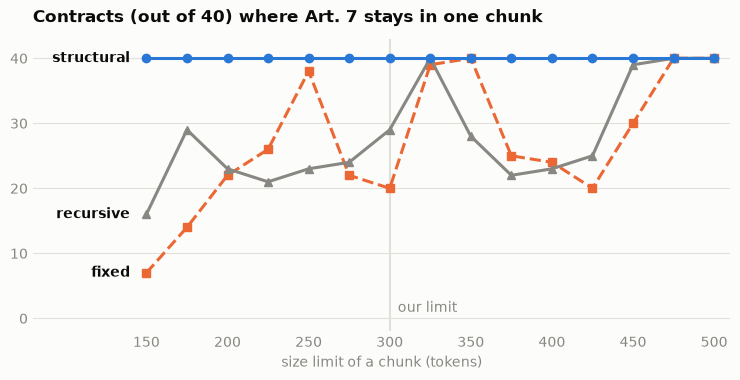

In [8]:
LOOK = {"fixed": (ORANGE, "--", "s"), "recursive": (MUTED, "-", "^"), "structural": (BLUE, "-", "o")}
limit = config.chunking.max_tokens

figure, axis = plt.subplots(figsize=(9, 3.8))
axis.axvline(limit, color=GRID, linewidth=1.5)
axis.text(limit + 5, 1, "our limit", color=MUTED)
for strategy, (color, line, marker) in LOOK.items():
    axis.plot(SIZES, whole[strategy], color=color, linestyle=line, marker=marker, linewidth=2.2, markersize=6)
    axis.text(SIZES[0] - 10, whole[strategy][0], strategy, ha="right", va="center", fontweight="bold")
axis.set_xticks(SIZES[::2])
axis.set_yticks(range(0, len(contracts) + 1, 10))
axis.set_xlim(SIZES[0] - 70, SIZES[-1] + 10)
axis.set_ylim(-2, len(contracts) + 3)
axis.set_xlabel("size limit of a chunk (tokens)", color=MUTED)
axis.tick_params(length=0, colors=MUTED)
axis.yaxis.grid(True, color=GRID, linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[:].set_visible(False)
title = f"Contracts (out of {len(contracts)}) where Art. 7 stays in one chunk"
axis.set_title(title, loc="left", fontweight="bold", pad=12)
plt.show()

`structural` keeps the article whole in every contract, whatever the size.

`fixed` and `recursive` jump up and down: 25 tokens more or less, and the article breaks in half of the
contracts or is whole again. There is no trend to follow. The contracts share one template, so Art. 7 sits
at about the same distance from the top in all of them: whether a cut falls inside it is luck.

And a size that is lucky for one article is unlucky for another:

In [9]:
for article in (7, 8):
    count = whole_in("fixed", 500, article)
    print(f"fixed, chunks of 500 tokens: Art. {article} is whole in {count} of {len(contracts)} contracts")

fixed, chunks of 500 tokens: Art. 7 is whole in 40 of 40 contracts
fixed, chunks of 500 tokens: Art. 8 is whole in 19 of 40 contracts


With `fixed` and `recursive` no size is safe for every article. With `structural` the limit matters only
for a section longer than the limit, and that section is split on purpose, with its heading repeated.

## How big are the chunks?

The three strategies on the whole corpus, with the limit of 300 tokens.

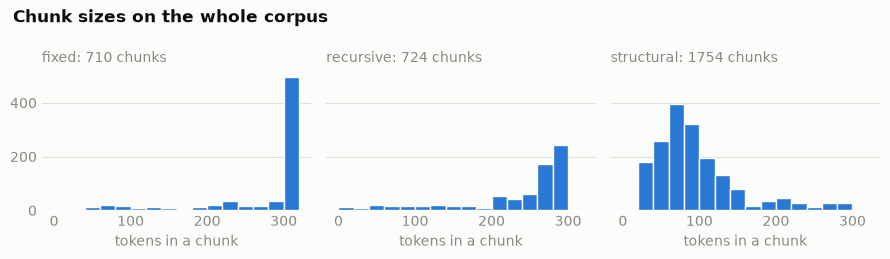

structural, median chunk: 84 tokens
structural chunks: 1754 - without the size limit: 1706


In [10]:
corpus_chunks, sizes = {}, {}
for strategy in STRATEGIES:
    corpus_chunks[strategy] = [chunk for document in documents for chunk in cut(document, strategy)]
    sizes[strategy] = [count_tokens(tokenizer, chunk.text) for chunk in corpus_chunks[strategy]]

figure, axes = plt.subplots(1, len(STRATEGIES), figsize=(9, 2.6), sharey=True)
for axis, strategy in zip(axes, STRATEGIES, strict=True):
    axis.hist(sizes[strategy], bins=range(0, 321, 20), color=BLUE, edgecolor=SURFACE)
    axis.set_title(f"{strategy}: {len(sizes[strategy])} chunks", loc="left", color=MUTED, fontsize=10)
    axis.set_xlabel("tokens in a chunk", color=MUTED)
    axis.tick_params(length=0, colors=MUTED)
    axis.yaxis.grid(True, color=GRID, linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[:].set_visible(False)
figure.suptitle("Chunk sizes on the whole corpus", x=0.02, ha="left", fontweight="bold")
figure.tight_layout()
plt.show()

unlimited = config.embedding.max_length
no_limit = sum(len(cut(document, "structural", max_tokens=unlimited)) for document in documents)
print("structural, median chunk:", int(np.median(sizes["structural"])), "tokens")
print("structural chunks:", len(sizes["structural"]), "- without the size limit:", no_limit)

`fixed` and `recursive` fill every chunk up to the limit: we decide the size. With `structural` the
document decides: one section, one chunk, most of them between 20 and 140 tokens.

The limit of 300 tokens rarely matters: without it there would be 1706 chunks instead of 1754.
A section longer than the limit is split, and every part repeats the heading.

## A detail: titles without a body

Docling marks the title of a contract and its number as two headings. Cutting on every heading
gives chunks that hold only a title. They answer no question, but they look similar to many questions.

In [11]:
def show_first(chunks: list[Chunk]) -> None:
    """Print the first three chunks, one per line, with paragraphs separated by a bar."""
    for chunk in chunks[:3]:
        print(f"  chunk {chunk.index}:", " | ".join(chunk.text.split("\n\n"))[:96])


print("no minimum size:")
show_first(cut(hero, "structural", min_tokens=0))
print(f"\nminimum of {config.chunking.min_tokens} tokens (smaller sections join the next one):")
show_first(cut(hero, "structural"))

no minimum size:
  chunk 0: ## CONTRATTO DI MANUTENZIONE
  chunk 1: ## n. CTR-2024-017
  chunk 2: ## tra | Torrevalle Acque S.p.A., con sede legale in Via dei Mulini 14, Borgo Torrevalle, codice

minimum of 20 tokens (smaller sections join the next one):
  chunk 0: ## CONTRATTO DI MANUTENZIONE | ## n. CTR-2024-017 | ## tra | Torrevalle Acque S.p.A., con sede l
  chunk 1: ## e | Beta Idroservizi S.r.l., con sede legale in Viale delle Officine 21, Castelrovo, codice f
  chunk 2: ## premesso che | - a) il Committente gestisce impianti di captazione, sollevamento e depurazion


With the minimum size the title, the contract number and the first party travel together: one useful chunk
instead of two empty ones.

## The trap: the same words in forty contracts

Art. 7 of the three contracts signed with the same supplier, Beta Idroservizi:

In [12]:
structural = corpus_chunks["structural"]
for chunk in structural:
    if "_Beta_" in chunk.source and chunk.section == "Art. 7 - Recesso":
        print(chunk.source.split("/")[1][:12], "|", chunk.text.split("\n\n")[1])

CTR-2023-009 | Il Committente può recedere dal contratto in qualsiasi momento, con preavviso di 90 (novanta) giorni.
CTR-2024-017 | Il Committente può recedere dal contratto in qualsiasi momento, con preavviso di 60 (sessanta) giorni.
CTR-2025-030 | Il Committente può recedere dal contratto in qualsiasi momento, con preavviso di 30 (trenta) giorni.


Same supplier, same article, same sentence: only the number changes. **Nothing in the text says which
contract it is.** A retriever that sees only the text cannot tell these three chunks apart, and neither can
the model that reads them.

How common is this? We count the chunks that are word for word identical to a chunk of another document.

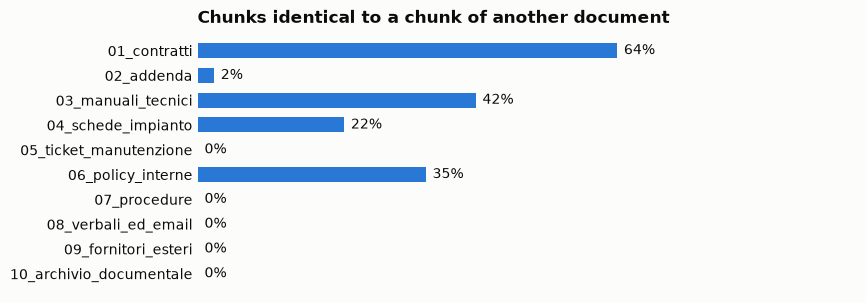

734 of 1754 chunks have an identical twin


In [13]:
copies = Counter(chunk.text for chunk in structural)
folders = sorted({chunk.source.split("/")[0] for chunk in structural})
share = {
    folder: np.mean([copies[chunk.text] > 1 for chunk in structural if chunk.source.startswith(folder)]) * 100
    for folder in folders
}

figure, axis = plt.subplots(figsize=(8.5, 3.4))
bars = axis.barh(folders, list(share.values()), color=BLUE, height=0.6)
axis.bar_label(bars, labels=[f"{value:.0f}%" for value in share.values()], padding=5, color=INK)
axis.invert_yaxis()
axis.set_xlim(0, 100)
axis.set_xticks([])
axis.tick_params(length=0, colors=INK)
axis.spines[:].set_visible(False)
axis.set_title("Chunks identical to a chunk of another document", loc="left", fontweight="bold")
plt.show()
twins = sum(copies[chunk.text] > 1 for chunk in structural)
print(f"{twins} of {len(structural)} chunks have an identical twin")

Two chunks out of five are copies: standard clauses in the contracts, safety chapters in the manuals,
sections that did not change between two versions of a policy. A search for the governing law returns
forty identical chunks.

This is why a chunk is not only text. It also carries where it comes from:

In [14]:
chunk = next(chunk for chunk in hero_chunks["structural"] if chunk.section.startswith("Art. 7"))
print("source: ", chunk.source)
print("section:", chunk.section)
print("page:   ", chunk.page)

source:  01_contratti/CTR-2024-017_Beta_manutenzione-pompe-sommergibili-p7-p9.pdf
section: Art. 7 - Recesso
page:    2


## What we take away

- **`fixed`** is the simplest and it is blind: at our limit it broke the withdrawal article in half of the
  contracts, and another limit only moves the damage to another article.
- **`recursive`** respects paragraphs but not articles: a heading can end up in one chunk and its text
  in the next one.
- **`structural`** follows the document: one article, one chunk, with its heading. It works because
  Docling gave us the headings in step 0.

**Choice: structural, limit of 300 tokens, sections under 20 tokens joined to the next one**
(section `chunking` of `src/conf/config.yaml`).

Two things stay open for the next steps:

1. the text of a chunk does not say which document it belongs to: when we embed and when we build the
   prompt, `source` and `section` have to be used, not just stored;
2. a table longer than the limit is cut between rows, and the parts after the first lose the header row.